<center><h1> ETI195 - Ética para Ciencia de Datos y Estadística </h1><center>
<center><h2> Taller Sumativo 4: Human Rights approach to data y privacidad <h2><center>


# Human Rights approach to data y privacidad

>Contexto

En estos talleres, estamos trabajando con datos que pueden influir en vidas de personas. Esto implica una responsabilidad ética especial, las personas o grupos de personas detrás pueden verse impactadas tanto de forma positiva como negativa con las decisiones basadas en datos que tomemos. Antes de hacer cualquier análisis, debes preguntarte cómo tratarías esos datos si fueras quien los recolecta, y cómo podrías compartirlos si resguardar la identidad de los involucrados fuese prioridad.

>Objetivos

El objetivo de este taller es diseñar un marco de recolección de datos basado en derechos humanos sobre los problemas que han estado tratando, así como identificar si cumplen o no con el marco regulatorio chileno, aplicar DataSynthesizer para generar una versión sintética del dataset, generar visualizaciones y proponer mejoras al dataset desde la perspectiva del activismo de datos.

> # instrucciones generales

Esta es la parte IV del proyecto, consideren utilizar sus resultados anteriores y reciclar el código de los talleres previos. El taller puede aplicarse sobre cualquiera de los tres datasets del proyecto; trabajen con el mismo dataset que eligieron en los talleres anteriores y respondan cada pregunta en función de ese contexto.

Si trabajan con CIRI, notarán que sus datos son indicadores agregados por país y año, por lo que no contienen información personal que deba protegerse. Aun así, la idea es que aprendan a utilizar las herramientas de privacidad diferencial y generación de datos sintéticos, ya que el procedimiento es el mismo independiente del dataset, y que reflexionen sobre qué ocurriría si estos datos tuvieran un mayor nivel de detalle, por ejemplo, registros individuales de víctimas, como se plantea en la pregunta 6.

## `Temas formales`

Modalidad: Grupos de 3 personas.

Fecha de entrega: 20 de noviembre.

Formato de entrega: El trabajo debe entregarse a través de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

Formalidades de las respuestas:
- Citas: APA 7.
- Se espera buena ortografía y redacción, con respuestas en tono académico.
- No respondan con simples "sí" o "no", consideren argumentar sus respuestas y justificar con bibliografía si lo estiman necesario.

## `Integridad académica y uso de IA`

El uso de asistentes de IA sigue los lineamientos de integridad académica del curso, con las siguientes excepciones:

- Pueden usar IA para consultar por bugs y entender mejor el código.
- Pueden usar IA para generar las representaciones visuales que estimen convenientes.

Si tienen dudas sobre el uso de IA o la citación de código externo, no duden en preguntar. Pueden usar libremente los códigos de los talleres formativos. <3

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de código y consulten sus dudas con sus ayudantes :D.



In [11]:
# Importación de librerías

import pandas as pd


### _`Importantes: A lo largo del notebook habrán preguntas guías para los análisis de resultados, operación de código y otros, se espera que las respondan o hagan alusión a ellas en sus respuestas `_

<br><br>
**`Pregunta (1`) Describa el objetivo y las variables del dataset desde una perspectiva distinta**.

¿A simple vista, consideras que alguna de estas variables podría ser mal utilizada, perjudicando a alguna comunidad?

¿Por qué crees que se consideran esas variables y no otras para el objetivo del dataset?
<br><br>

Algunas variables que pueden ser mal utilizadas son las de género, terapia con hormonas y estado de menopausia. Históricamente han existido propagandas que aluden al miedo, culpa o inseguridad femenina a través del envejecimiento, cosméticos, ropa, olor corporal, etc. Con el fin de generar consumo y así aumentar ventas. Tratándose de un dataset de cancer mama, enfermedad que es más frecuente en mujeres, no resultaría extraño pensar que diferentes empresas o marcas puedan apelar a la urgencia de comprar un producto o temor respecto a la enfermedad para obtener dinero. Esto podría perjudicar a mujeres y en general a la comunidad que padece este cáncer al jugar con emociones y miedos.

Por otro lado también podríamos fijarnos en la columna de ingreso anual (USD). Podría ser mal utilizada al tomar cierta cantidad de dinero como referencia de que una persona puede costearse el tratamiento o exámenes si lo necesita. ¿Qué pasaría si alguien pierde su trabajo o directamente no lo puede costear? También podríamos ver ingresos muy bajos se decidiera segregarlo para no cubrir gastos médicos. Esto podría perjudicar a diferentes personas porque se podría negar el acceso de salud. 

Nuestro objetivo es predecir si una persona tiene o no cáncer de mama. Como es una enfermedad asociada principalmente a mujeres, un grupo afectado a lo largo de los años por brechas económicas y de género, por eso elegimos estas variables.



### `2: Exploración de datos y limpieza.`

Basta con que lo hayan realizado en los talleres anteriores, solo consideren usar el dataset limpio para lo que viene.

In [12]:
# Definir ruta de los datos
path = "breast_cancer_prediction.csv"

# Leemos el archivo csv y lo guardamos en un dataframe
df = pd.read_csv(path)

In [13]:
# Se mostraran las primeras 10 filas del dataframe
df.head(10)

,Patient_ID,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,...,Mammogram_Result,Biopsy_Result,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD
0,100001,71,Female,27.2,Yes,Yes,Yes,High,No,Post,...,Suspicious,Malignant,Stage II,1,141,167,No,7,No,101316
1,100002,34,Male,26.0,No,No,No,High,No,Post,...,Normal,Benign,No Cancer,0,104,229,Yes,7,Yes,30023
2,100003,80,Female,20.7,No,No,No,High,No,Pre,...,Suspicious,Benign,No Cancer,0,161,275,No,1,Yes,34819
3,100004,40,Female,26.8,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,150,180,No,7,Yes,68025
4,100005,43,Female,28.6,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,110,266,No,0,Yes,90919
5,100006,22,Female,18.8,No,No,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,172,270,No,3,Yes,51320
6,100007,41,Female,31.8,Yes,No,Yes,High,No,Post,...,Normal,Benign,No Cancer,0,176,297,No,7,No,47235
7,100008,72,Male,23.8,No,Yes,No,High,No,Post,...,Normal,Benign,No Cancer,0,164,184,No,5,Yes,102525
8,100009,21,Female,26.1,No,No,No,High,No,Post,...,Normal,Benign,No Cancer,0,164,238,No,0,Not Applicable,47668
9,100010,49,Female,29.7,Yes,No,Yes,Moderate,No,Pre,...,Normal,Benign,No Cancer,0,177,300,No,0,Yes,83068


In [14]:
print(df["Gender"].unique())

['Female' 'Male']


In [15]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'BMI', 'Family_History', 'Smoking',
       'Alcohol_Consumption', 'Physical_Activity', 'Hormone_Therapy',
       'Menopause_Status', 'Genetic_Mutation', 'Tumor_Size_cm',
       'Lymph_Node_Involvement', 'Mammogram_Result', 'Biopsy_Result',
       'Cancer_Stage', 'Cancer', 'Blood_Pressure', 'Cholesterol', 'Diabetes',
       'Exercise_Days_Per_Week', 'Breastfeeding_History', 'Annual_Income_USD'],
      dtype='object')

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Patient_ID              10000 non-null  int64  
 1   Age                     10000 non-null  int64  
 2   Gender                  10000 non-null  object 
 3   BMI                     9700 non-null   float64
 4   Family_History          10000 non-null  object 
 5   Smoking                 10000 non-null  object 
 6   Alcohol_Consumption     9700 non-null   object 
 7   Physical_Activity       9700 non-null   object 
 8   Hormone_Therapy         9700 non-null   object 
 9   Menopause_Status        10000 non-null  object 
 10  Genetic_Mutation        10000 non-null  object 
 11  Tumor_Size_cm           9700 non-null   float64
 12  Lymph_Node_Involvement  10000 non-null  object 
 13  Mammogram_Result        10000 non-null  object 
 14  Biopsy_Result           10000 non-null 

Siguiendo la clasificación de datos del Taller 1:

**1. Clasificación de variables.**

Variables númericas (cuantitativas):

- ID del paciente (Número entero) (Funciona como un identificador, no un número que podamos promediar).
- Edad (Número entero).
- BMI (Índice de Masa Corporal) (Número decimal).
- Tamaño del tumor en cm (Número decimal).
- Cancer (Número entero).
- Presión arterial (Número entero).
- Colesterol (Número entero).
- Número de dias de ejercicio a la semana (Número entero).
- Ingresos anuales en dólares estadounidenses (Número entero).

Variables categóricas(cualitativas):
- Género.
- Historial médico familiar.
- Fumar.
- Consumo de alcohol.
- Actividad física.
- Terapia hormonal.
- Estado menopáusico.
- Mutación genética.
- Afección de los ganglios linfáticos.
- Resultados de mamografía.
- Resultados de biopsia.
- Etapa del cancer.
- Diabetes.
- Historial de lactancia materna.

**2. Atributos demográficos y sensibles.**

En el contexto médico, los atributos demográficos se refieren a la información personal y de identificación que se compilan durante su registro al sistema médico.

- Edad.
- Género.
- Ingresos anuales en dálares estadounidenses (contextualiza la posición econámica del paciente).

Mientras que los atributos sensibles, se refieren a aquellos que su divulgación puede causar daño, discriminación o violación a la privacidad del paciente.

- Cancer.
- Fumar.
- Consumo de alcohol.
- Terapia hormonal.
- Estado menopáusico.
- Mutación genética.
- Resultados de mamografía.
- Resultados de biopsia.
- Etapa del cancer.
- Diabetes.

**3. Datos en formato incorrecto.**

- ID del paciente. Esta variable se encuentra en formato de número entero, esto significa que es posible aplicarle estadisticas como mediana, moda o promedio. Sin embargo, esta variable tiene como finalidad representar e identificar al paciente, por lo que, un string es la mejor opción para evitar operaciones estadisticas innecesarias sobre la columna.

- Cáncer. Esta variable se encuentra representada por un número entero, sin embargo, creemos que un tipo de dato categórico sería lo mejor para representar a las dos opciones: "Tiene cancer" o "No tiene cancer", además no corremos el riesgo (como en la variable anterior) de que se intente realizar operaciones estadísticas inservibles sobre esta.

In [17]:
# Cambiar "Cancer" a tipo categórico
df["Cancer"] = df["Cancer"].astype("category")

# Cambiar "Patient_ID" a string
df["Patient_ID"] = df["Patient_ID"].astype(str)

# Verificamos que los datos se hayan cambiado correctamente
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   Patient_ID              10000 non-null  object  
 1   Age                     10000 non-null  int64   
 2   Gender                  10000 non-null  object  
 3   BMI                     9700 non-null   float64 
 4   Family_History          10000 non-null  object  
 5   Smoking                 10000 non-null  object  
 6   Alcohol_Consumption     9700 non-null   object  
 7   Physical_Activity       9700 non-null   object  
 8   Hormone_Therapy         9700 non-null   object  
 9   Menopause_Status        10000 non-null  object  
 10  Genetic_Mutation        10000 non-null  object  
 11  Tumor_Size_cm           9700 non-null   float64 
 12  Lymph_Node_Involvement  10000 non-null  object  
 13  Mammogram_Result        10000 non-null  object  
 14  Biopsy_Result          

In [18]:
# Valores nulos

df.isnull().sum()

Patient_ID                  0
Age                         0
Gender                      0
BMI                       300
Family_History              0
Smoking                     0
Alcohol_Consumption       300
Physical_Activity         300
Hormone_Therapy           300
Menopause_Status            0
Genetic_Mutation            0
Tumor_Size_cm             300
Lymph_Node_Involvement      0
Mammogram_Result            0
Biopsy_Result               0
Cancer_Stage                0
Cancer                      0
Blood_Pressure              0
Cholesterol                 0
Diabetes                    0
Exercise_Days_Per_Week      0
Breastfeeding_History       0
Annual_Income_USD           0
dtype: int64

In [19]:
# Datos atípicos

df.describe()

,Age,BMI,Tumor_Size_cm,Blood_Pressure,Cholesterol,Exercise_Days_Per_Week,Annual_Income_USD
count,10000.000000,9700.000000,9700.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,52.033800,27.051227,2.630334,134.811100,214.071500,3.535200,82337.305000
std,18.789517,4.494501,1.589789,26.174742,49.242034,2.282385,39102.629984
min,20.000000,11.100000,0.000000,90.000000,130.000000,0.000000,15002.000000
25%,36.000000,24.000000,1.370000,112.000000,172.000000,2.000000,48145.750000
50%,52.000000,27.000000,2.510000,135.000000,213.000000,4.000000,81813.500000
75%,68.000000,30.100000,3.720000,157.000000,257.000000,6.000000,116217.500000
max,84.000000,44.100000,9.880000,180.000000,300.000000,7.000000,149996.000000


### `3: Análisis de principios.`

**`Pregunta (3)` Identifique si el dataset seleccionado cumple con los principios de Human Rights approach to data. Si cumple, explique por qué cumple. Si no cumple, proponga un nuevo marco de recolección o tratamiento que sí cumpla.**

Recuerda apoyarte en bibliografía externa, puedes sugerir marcos y métodos de tratamiento de datos utilizados en casos similares. Argumenta sólidamente tu elección.


***Participación***: No tiene, ya que los datos son sintéticos, usados para el aprendizaje de Machine learning, por lo tanto no posee participación de   pacientes.
  Propondría hacer la recolección básica de datos recolectando, por ejemplo en Chile de todas las regiones y en hospitales públicos y privados,     intentando hacer la población lo más variada posible.

***Desagregación***: Posee, al tener categorías para dividir como género, edad, antecedentes familiares, ingreso anuales pero para realmente realizar un análisis profundo y detectar desigualdades no visibles en un conjunto grande, faltan categorías como identidad de género porque solo tenemos las opciones mujer y hombre en género, la etnia y el territorio.

***Autoidentificacion***: No cumple por el solo hecho que no hay personas detrás de los datos, son sintéticos, por esto es imposible que las personas se puedan puedan opinar sobre identificación.
Al igual que en participación la dificultad está en no tener población real, por esto haría lo mismo pero agregando que la población deben tener la opción de revelar o retener información sobre sus características personales y el poder decidir identificarse (por ejemplo la identidad de género).

***Transparencia***: Cumple de manera muy precaria,tenemos los datos públicos pero no información sobre el código por esto no conocemos si se basaron en datos clínicos reales para crear los sintéticos o que clase de módulo de DataSynthesizer usaron, provocando que no haya una forma de saber porque razón tenemos datos nulos que serian en total 1500, 300 es 5 columnas.

***Privación:*** Sí hay, debido a que los datos son sintéticos, eso quiere decir que no hay forma de vulnerar la información médica de los pacientes utilizando solo esos datos, pero es si se usan los mismos datos con pacientes reales para comparar lo aprendido a la realidad, dejaría expuesta mucha información médica altamente sensible. 

***Rendición de cuentas***: No cumple a pesar que en Kaggle dice ser para estudio y aprendizaje, al final es un repertorio abierto y no hay un garante que haga respetar, proteger y cumplir los derechos humanos, en otras palabras si el modelo llegara a aprender con sesgos nada evitaría que se usara en contexto real y que nadie se haga responsable de las consecuencias.
Propondría que una institución como lo es el ministerio de salud(MINSAL) establesca un comité supervisor que pueda gestionar este tipo de situaciones y prevenir el mal uso de los datos o el uso de datos segregados.


<br><br>
### `4: Análisis regulatorio.`

**`Pregunta (4)` Proponga un método de recolección de este tipo de datos imaginando que fuese requerido para Chile. El método debe cumplir con el marco regulatorio chileno, considerando las políticas que entraron y entrarán en vigencia.**

Al momento de explicar el método propuesto, recuerda hacer alusión a principios, temas y/o artículos específicos de la regulación vigente o de discusiones académicas en torno a esta.



<br><br>
### `5: Privacidad diferencial.`

**`Pregunta (5)` Aplica las técnicas de privacidad diferencial vistas para anonimizar el dataset y comenta los resultados.**

      - Selecciona a lo más 7 variables para aplicar la técnica. Menciónalas y justifica tu elección.
      - Obtenga la descripción del dataset en alguno de los modos, justifique su elección. Guarde dicha descripción en un archivo local
      (en formato JSON)
      - Genere los datos sintéticos usando DataGenerator
      - Aplique ModelInspector para comparar las distribuciones entre los datos originales y los datos sintéticos.

<br><br>


**variables**: edad, genero, ingreso anual, tamaño del tumor, resultado de biopsia, cancer, antecedentes familiares
Las elejimos porque son de las más sensibles pero a la vez son de las más necesarias para que un modelo predisca el cáncer


In [27]:
import pandas as pd
import os
from DataSynthesizer.DataDescriber import DataDescriber
from DataSynthesizer.DataGenerator import DataGenerator
import DataSynthesizer.DataGenerator as dg
from DataSynthesizer.lib.utils import read_json_file
from DataSynthesizer.ModelInspector import ModelInspector
import numpy as np

cols = ["Age", "Gender",
    "Annual_Income_USD",
    "Tumor_Size_cm",
    "Biopsy_Result",
    "Cancer",    
    "Family_History"]
df_limpio = df[cols].dropna()

df_analyze = df[cols]
df_analyze.info()
df_analyze.to_csv("breast_cancer_prediction.csv", index=False)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   Age                10000 non-null  int64   
 1   Gender             10000 non-null  object  
 2   Annual_Income_USD  10000 non-null  int64   
 3   Tumor_Size_cm      9700 non-null   float64 
 4   Biopsy_Result      10000 non-null  object  
 5   Cancer             10000 non-null  category
 6   Family_History     10000 non-null  object  
dtypes: category(1), float64(1), int64(2), object(3)
memory usage: 478.8+ KB


In [28]:
source = "breast_cancer_prediction.csv" #path al archivo limpio

# Instanciamos a DataDescriber y DataGenerator.
describer = DataDescriber()
generator = DataGenerator()

In [29]:
# Generamos la descripción del dataset.
describer.describe_dataset_in_correlated_attribute_mode(source)

================ Constructing Bayesian Network (BN) ================
Adding ROOT Family_History
Adding attribute Tumor_Size_cm
Adding attribute Biopsy_Result
Adding attribute Cancer
Adding attribute Gender
Adding attribute Age
Adding attribute Annual_Income_USD
========================== BN constructed ==========================


Elegimos el modo Correlated ya que lo que nosotros queremos conservar con la relación que hay entre las variables y agregando ruido para anonimizar, pero como nuestros datos son sintéticos sería hacerlo por segunda vez. 


In [30]:
# Guardamos la descripción en un archivo local.
# ahora podemos revisar el archivo para entender mejor la estructura de los datos y cómo se relacionan entre sí
describer.save_dataset_description_to_file("correlated.json")

In [31]:
dg.np = np # type: ignore

# Generamos los datos sintéticos.
generator.generate_dataset_in_correlated_attribute_mode(n=2000, description_file="correlated.json", seed=0)

In [32]:
# Guardamos los datos sintéticos.
generator.save_synthetic_data("correlated.csv")

In [33]:
# Veamos que efectivamente se han creado datos sintéticos.
correlated = pd.read_csv("correlated.csv")
correlated.head()

,Age,Gender,Annual_Income_USD,Tumor_Size_cm,Biopsy_Result,Cancer,Family_History
0,68.0,Female,23160.0,5.367057,Benign,0,No
1,29.0,Female,27967.0,4.202965,Benign,0,Yes
2,53.0,Female,110826.0,1.096209,Benign,0,Yes
3,82.0,Female,124242.0,2.750386,Benign,1,No
4,41.0,Female,29708.0,2.484112,Benign,1,No


In [38]:
# Instanciamos ModelInspector

correlated_description = read_json_file("correlated.json")["attribute_description"]
c_inspector = ModelInspector(df_analyze.copy(), correlated.copy(), correlated_description)

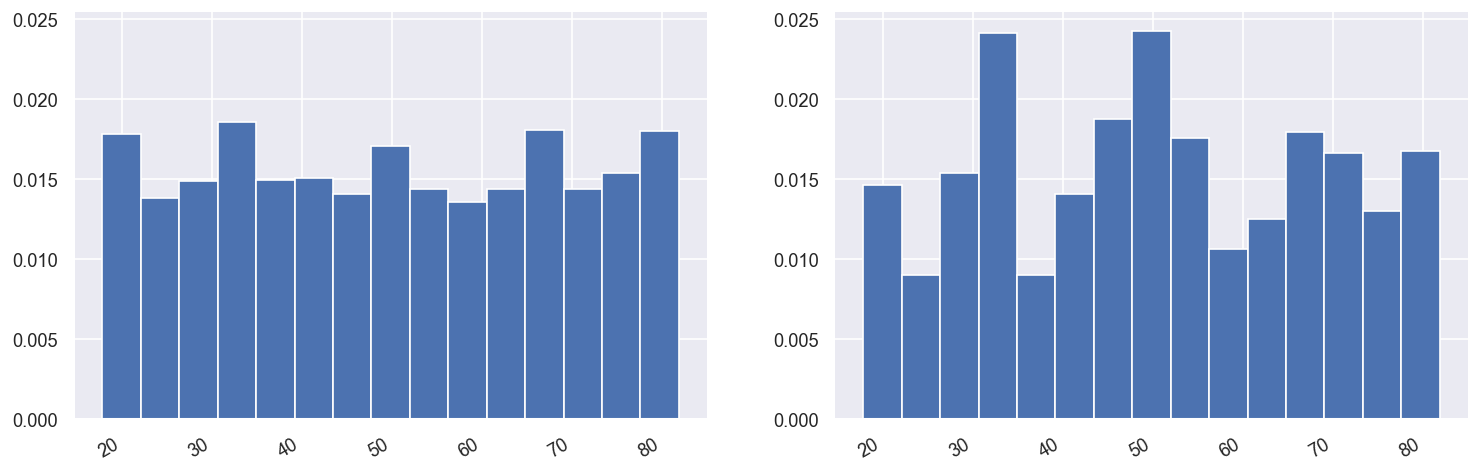

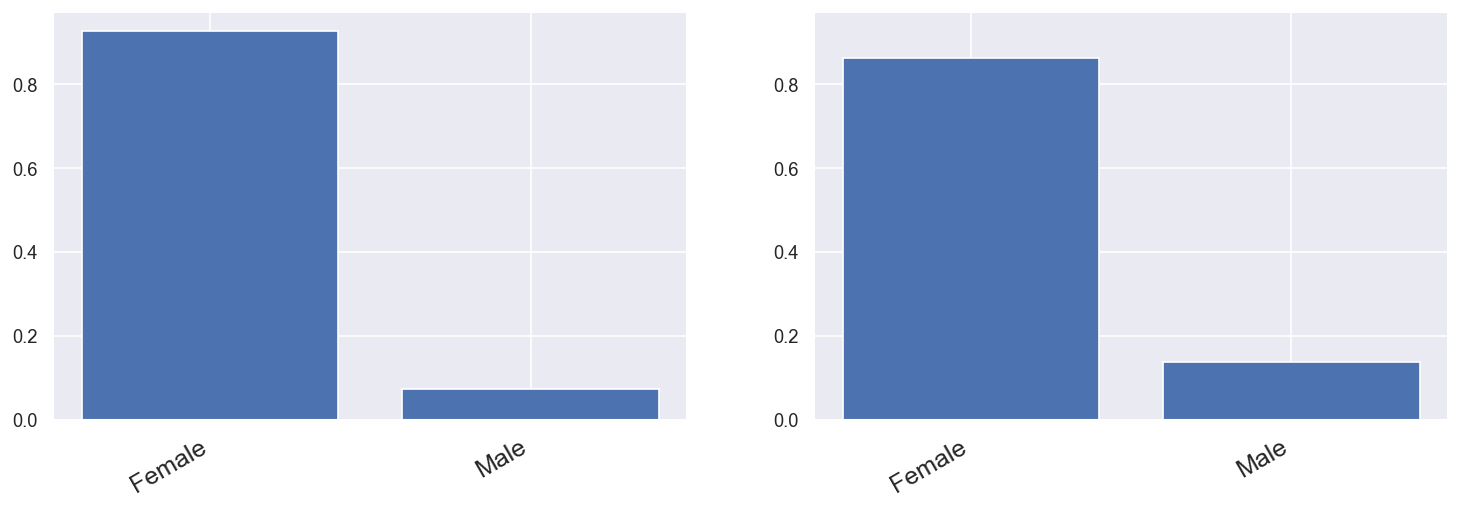

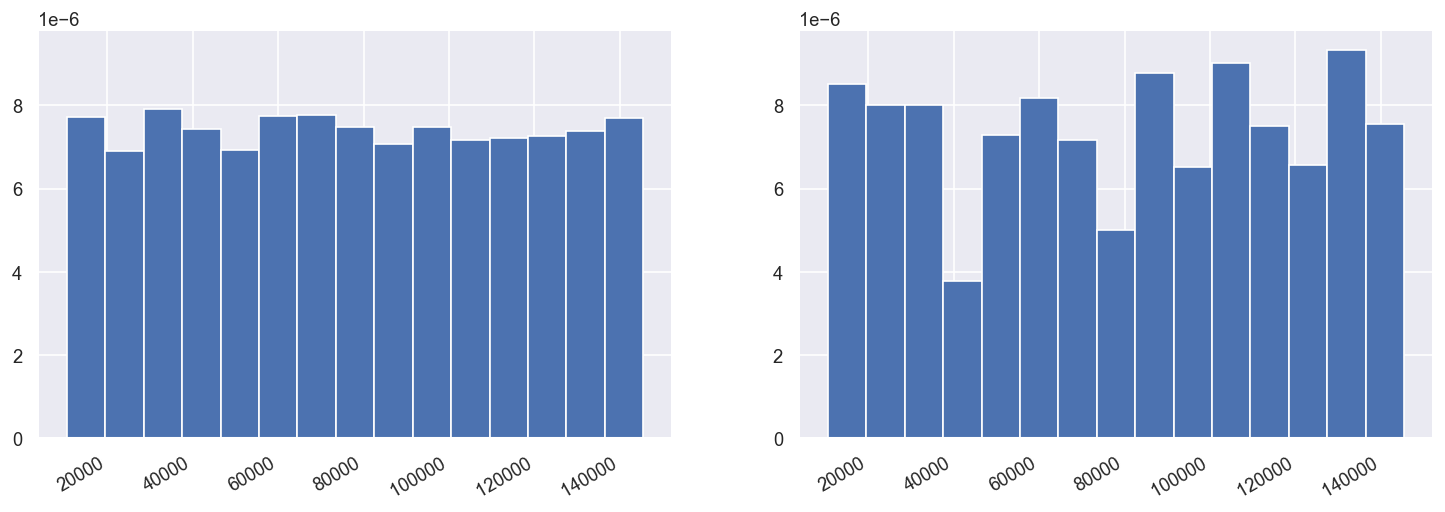

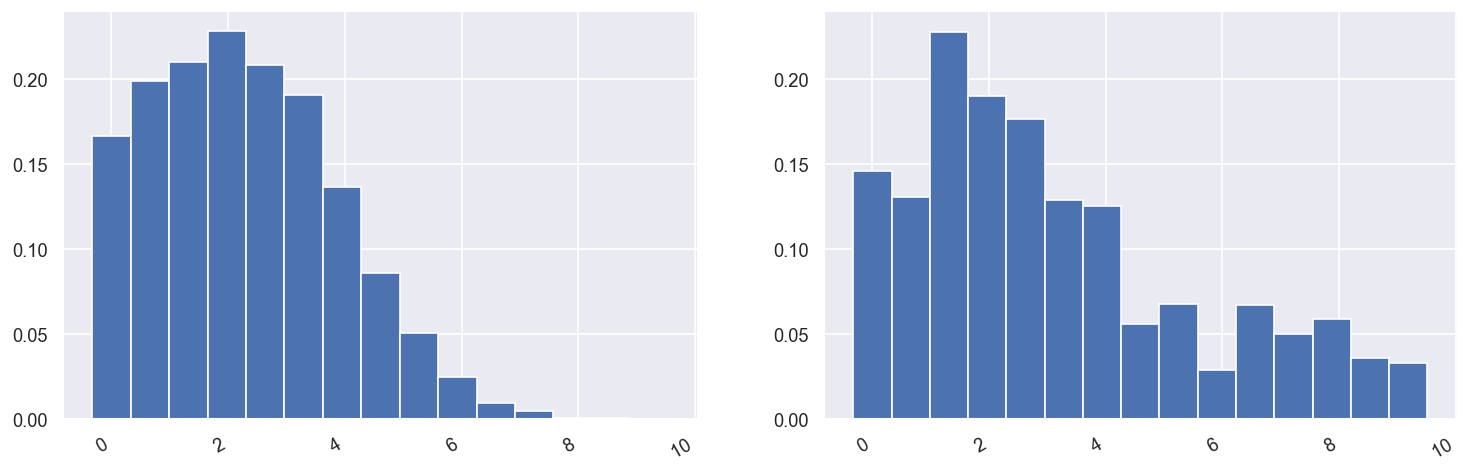

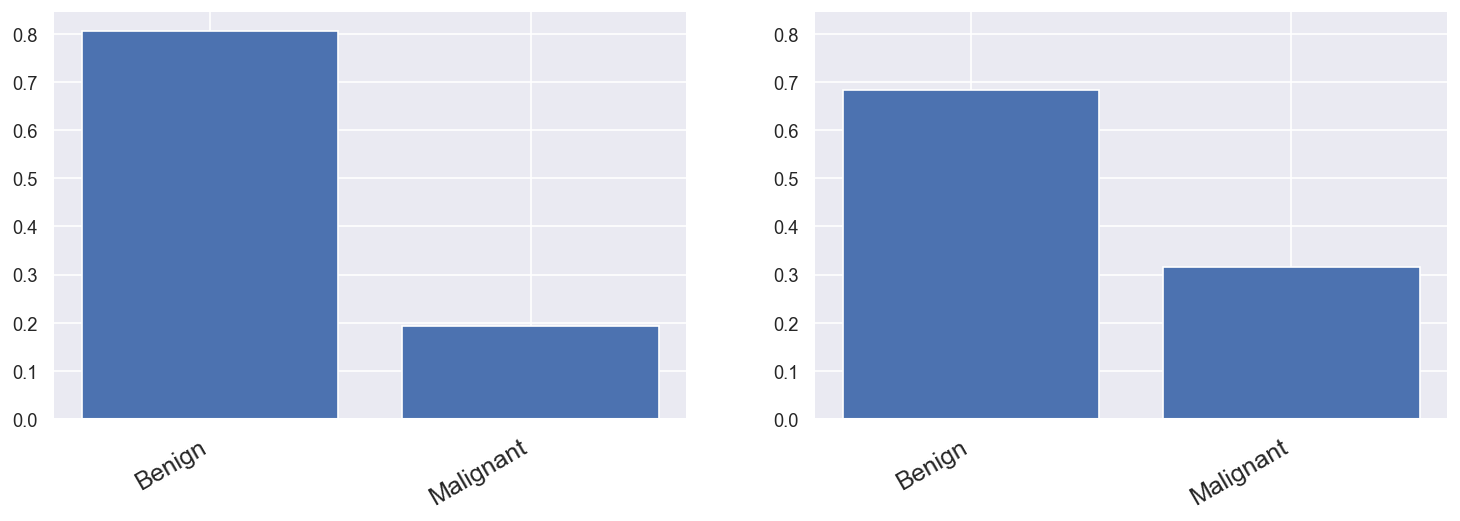

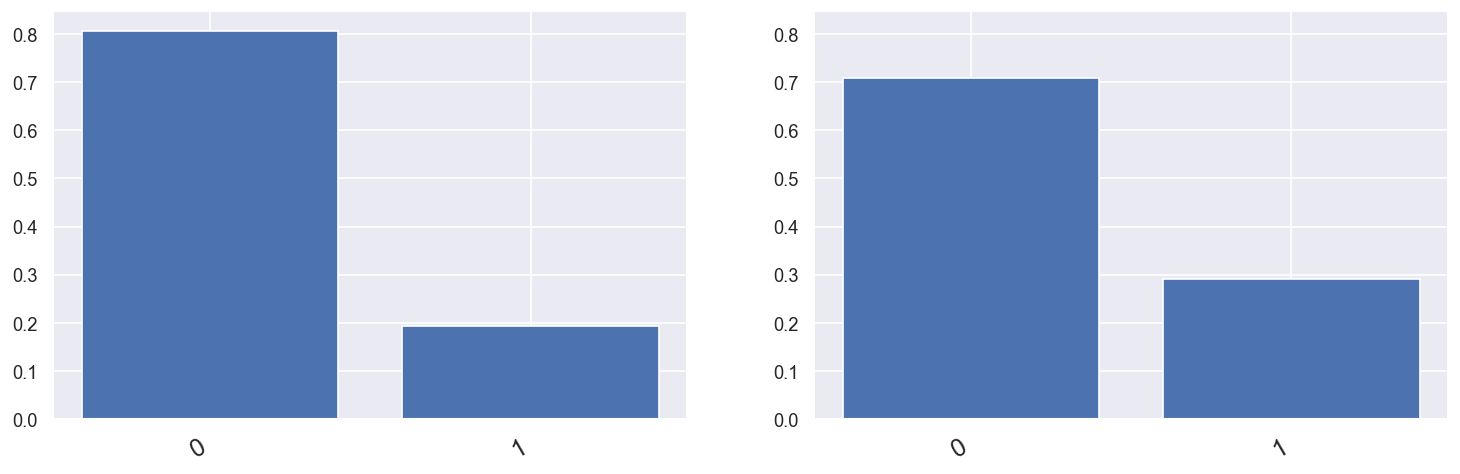

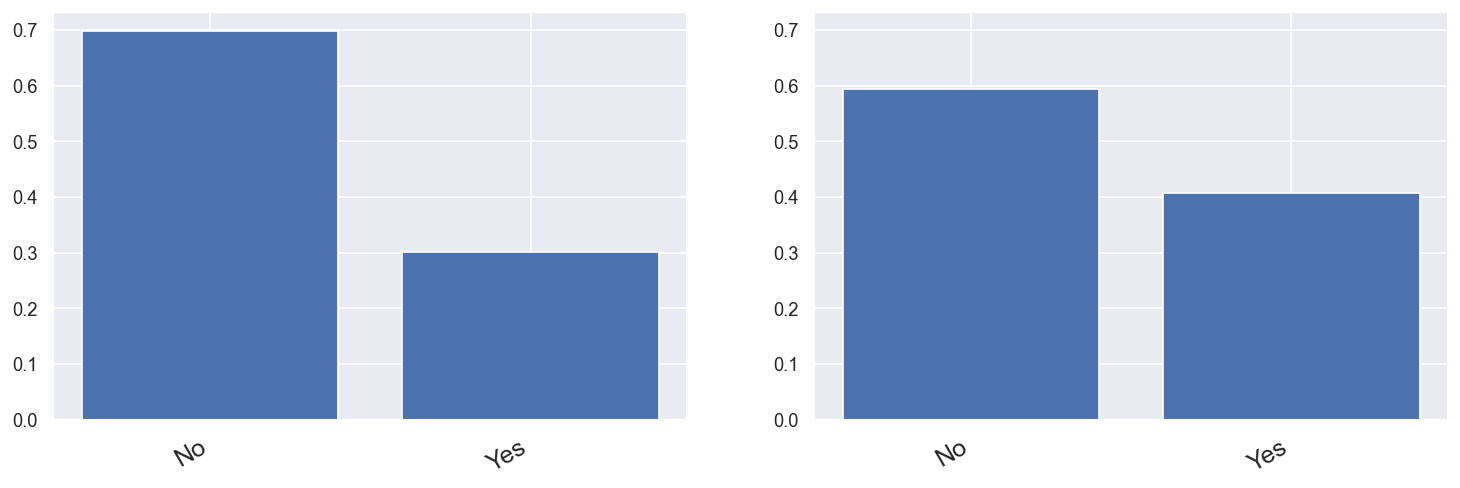

In [39]:
# Con ModelInspector podemos comparar las distribuciones de los atributos.
for attr in correlated.columns:
    c_inspector.compare_histograms(attr)

Imagina que ahora cuentas con este mismo dataset con información mucho más detallada, que podría contribuir a un proyecto desde la Ciencia de Datos con impacto social. Dependiendo del dataset que haya escogido su grupo, consideren el siguiente escenario:

- CIRI: el dataset incluye locaciones específicas, familias y detalles de investigación sobre desapariciones y asesinatos, lo que podría contribuir a un proyecto de búsqueda de víctimas.

- Salud: el dataset incluye identificadores de pacientes, centro de salud de atención y comuna de residencia, lo que podría contribuir a un proyecto de detección temprana o de acceso equitativo a tratamientos.

- CASEN: el dataset incluye la ubicación exacta de cada hogar, su composición familiar y el detalle de ingresos y beneficios recibidos, lo que podría contribuir a focalizar mejor la entrega de ayudas sociales.

En este caso podríamos preguntarnos, ¿qué sería lo correcto? ¿anonimizar o mantener pública toda la información?

**`Pregunta (6)` Proceso de toma de decisiones: Frente a este dilema concreto ¿incluir todos los datos por precisión y transparencia o aplicar técnicas de privacidad para proteger a las personas y sus familias? ¿cómo lo resolverías? cuales son los pros y los contras de esta decisión, en que tipo de contextos compartirías los datos reales y en cuales los datos sinteticos.**

Para este dilema definitivamente escogemos "técnicas de privacidad para proteger a las personas y sus familias" ya que los datos como identificadores de pacientes, centro de salud de atención y comuna de residencia son datos altamente sencibles y fáciles de desencriptar para la reidentificación de las personas pudiendo ocacionar discriminación laboral, estigmatización social, etc.

Lo resolvería eliminando datos que son identificadores directos como un rut, nombre completo, etc y a los que son sencibles pero necesarios los agruparía en conjuntos más generales, cuidando la privacidad de las personas pero perdiendo exactitud en el análisis de los datos.

**Contextos para compartir datos reales:**
Para el Estado e instituciones Sanitarias, con sus investigaciones de salud en donde son proyectos cerrados que necesitan información lo más presisa posible para la detección de una enfermedad y la localización del paciente lo antes posible.
para investigaciones de universidades que cuenten con aprobación de un comité de ética y compromisos legales de confidencialidad.

**Contextos para compartir datos sintéticos:**
publicaión abierta para investigaciones independientes, ayudando a la investigación pero sin exponer a nadie.



In [ ]:
# código aquí.


### `6: Activismo de datos.`

**`Pregunta (7)` Reporte los resultados de la técnica de anonimización (ModelInspector) y explique como se podría realizar activismo de datos con el conjunto anonimizado.**



In [ ]:
# código aquí.